genes kept: 13174
       CSES9  CSES7  CSES22  CSES21  HUES14
chrom                                      
1       0.00   0.00    0.00    0.00    0.00
2       0.00   0.00    0.00    0.00    0.00
3       0.00   0.00    0.00    0.00    0.00
4       0.00   0.00    0.00    0.00    0.00
5      -0.00   0.00    0.00    0.00    0.00
6       0.00   0.00    0.00    0.00    0.00
7       0.00   0.00    0.00    0.00    0.00
8       0.00   0.00    0.00    0.00    0.00
9       0.00   0.00    0.00    0.01    0.00
10     -0.00   0.00    0.00    0.00    0.00
11      0.00   0.00    0.00    0.02    0.00
12     -0.02   0.00    0.48    0.00    0.00
13     -0.04   0.00    0.01    0.00    0.00
14      0.00   0.00    0.00    0.00    0.00
15      0.00   0.00    0.00    0.00    0.00
16      0.00   0.00    0.00    0.02    0.00
17     -0.02   0.11    0.00    0.00   -0.09
18      0.00   0.00    0.00   -0.06    0.00
19      0.00   0.00    0.00    0.00    0.00
20      0.00   0.00    0.00    0.00    0.00
21      0.00  

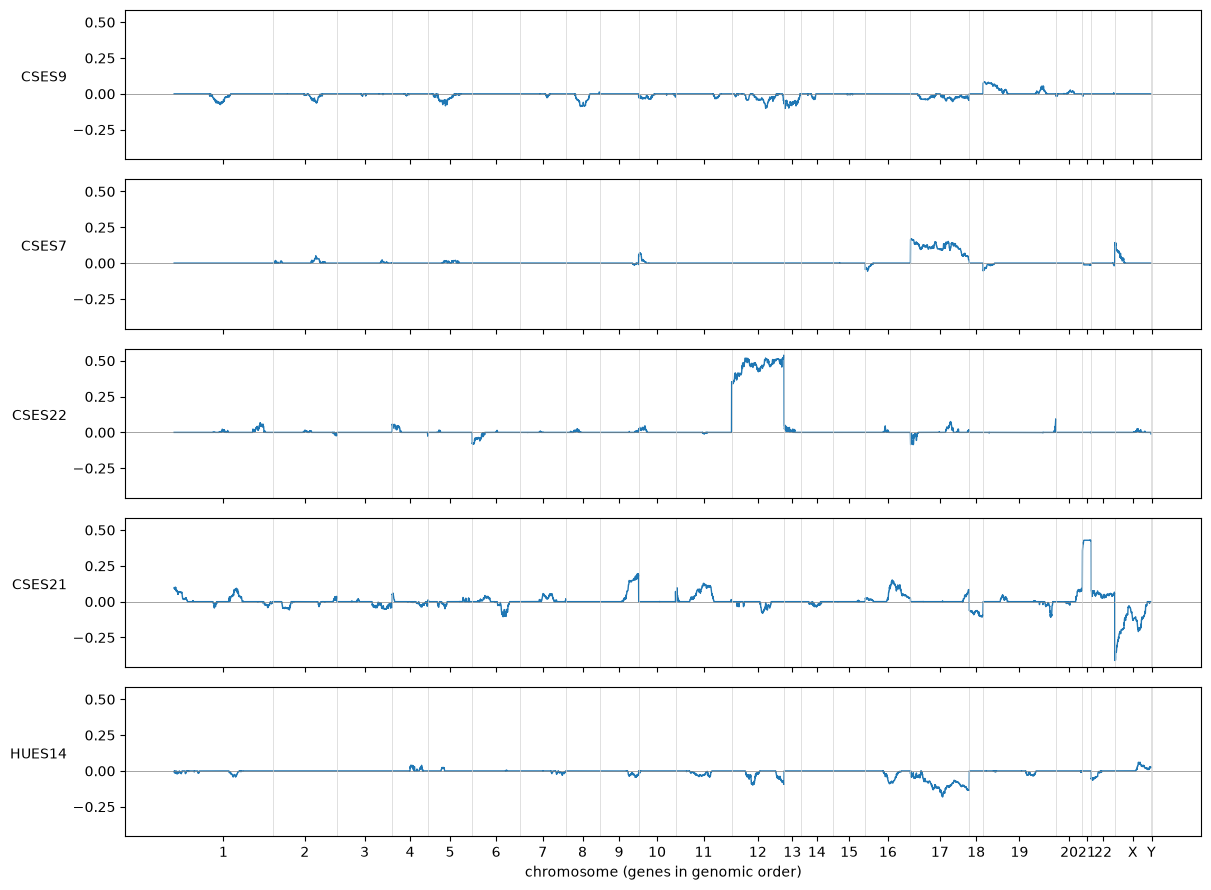

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

counts = pd.read_csv("../data/processed/gene_counts.csv", index_col=0)
genes = pd.read_csv("../data/processed/genes.csv", index_col=0)
genes["chrom"] = genes["chrom"].astype(str)

# ---- choices: record your reasons in docs/design.md ----
MIN_COUNTS = 20   # a gene needs at least this many estimated reads in EVERY sample
WINDOW = 200      # genes per smoothing window (the paper used 200 for its expression method)

# 1. keep reasonably expressed genes
keep_genes = (counts >= MIN_COUNTS).all(axis=1)
counts = counts[keep_genes]
genes = genes.loc[counts.index]
print("genes kept:", len(genes))

# 2. normalize for sequencing depth (counts per million), then log2
cpm = counts / counts.sum() * 1e6
logcpm = np.log2(cpm + 1)

# 3. compare each gene to its median across the five lines
ratio = logcpm.sub(logcpm.median(axis=1), axis=0)

# 4. order genes along the genome
order = {c: i for i, c in enumerate([str(i) for i in range(1, 23)] + ["X", "Y"])}
genes["chrom_order"] = genes["chrom"].map(order)
genes = genes.sort_values(["chrom_order", "start"])
ratio = ratio.loc[genes.index]

# 5. median ratio per chromosome (a first numeric check)
chrom_median = ratio.groupby(genes["chrom"]).median()
chrom_median = chrom_median.loc[sorted(chrom_median.index, key=lambda c: order[c])]
print(chrom_median.round(2))

# 6. smooth within each chromosome with a moving median
smooth = pd.DataFrame(index=ratio.index)
for s in ratio.columns:
    smooth[s] = ratio[s].groupby(genes["chrom"]).transform(
        lambda x: x.rolling(WINDOW, center=True, min_periods=WINDOW // 2).median())

# 7. plot: one panel per sample, genes in genomic order
sizes = genes.groupby("chrom_order").size()
names = genes.groupby("chrom_order")["chrom"].first()
bounds = sizes.cumsum().values
mid = bounds - sizes.values / 2

fig, axes = plt.subplots(len(smooth.columns), 1, figsize=(12, 9), sharex=True, sharey=True)
x = np.arange(len(smooth))
for ax, s in zip(axes, smooth.columns):
    ax.plot(x, smooth[s].values, lw=1)
    ax.axhline(0, color="grey", lw=0.5)
    for b in bounds:
        ax.axvline(b, color="lightgrey", lw=0.5)
    ax.set_ylabel(s, rotation=0, ha="right")
axes[-1].set_xticks(mid)
axes[-1].set_xticklabels(names.values)
axes[-1].set_xlabel("chromosome (genes in genomic order)")
plt.tight_layout()
os.makedirs("../figures", exist_ok=True)
plt.savefig("../figures/first_profile.png", dpi=150)
plt.show()

       CSES9  CSES7  CSES22  CSES21  HUES14
chrom                                      
1      -0.05   0.04    0.03    0.01   -0.04
2      -0.06   0.06    0.02   -0.02   -0.02
3      -0.04   0.05    0.01   -0.03    0.00
4      -0.06   0.06    0.03   -0.04    0.03
5      -0.10   0.09    0.03   -0.00    0.01
6      -0.04   0.04   -0.01   -0.01    0.02
7      -0.03   0.04    0.00    0.05   -0.06
8      -0.08   0.04    0.02   -0.01    0.01
9      -0.03   0.02    0.02    0.09   -0.06
10     -0.08   0.09    0.04    0.01   -0.04
11     -0.03   0.04   -0.03    0.08   -0.07
12     -0.12  -0.03    0.55   -0.06   -0.11
13     -0.12   0.07    0.09   -0.03    0.01
14     -0.06   0.04    0.01   -0.04   -0.01
15     -0.07   0.08    0.02   -0.04   -0.05
16      0.01  -0.03    0.01    0.10   -0.06
17     -0.11   0.22    0.03    0.05   -0.20
18     -0.03   0.07    0.00   -0.12    0.02
19      0.08  -0.02   -0.01    0.00   -0.06
20      0.06  -0.03   -0.03    0.02   -0.01
21     -0.07  -0.09   -0.05    0

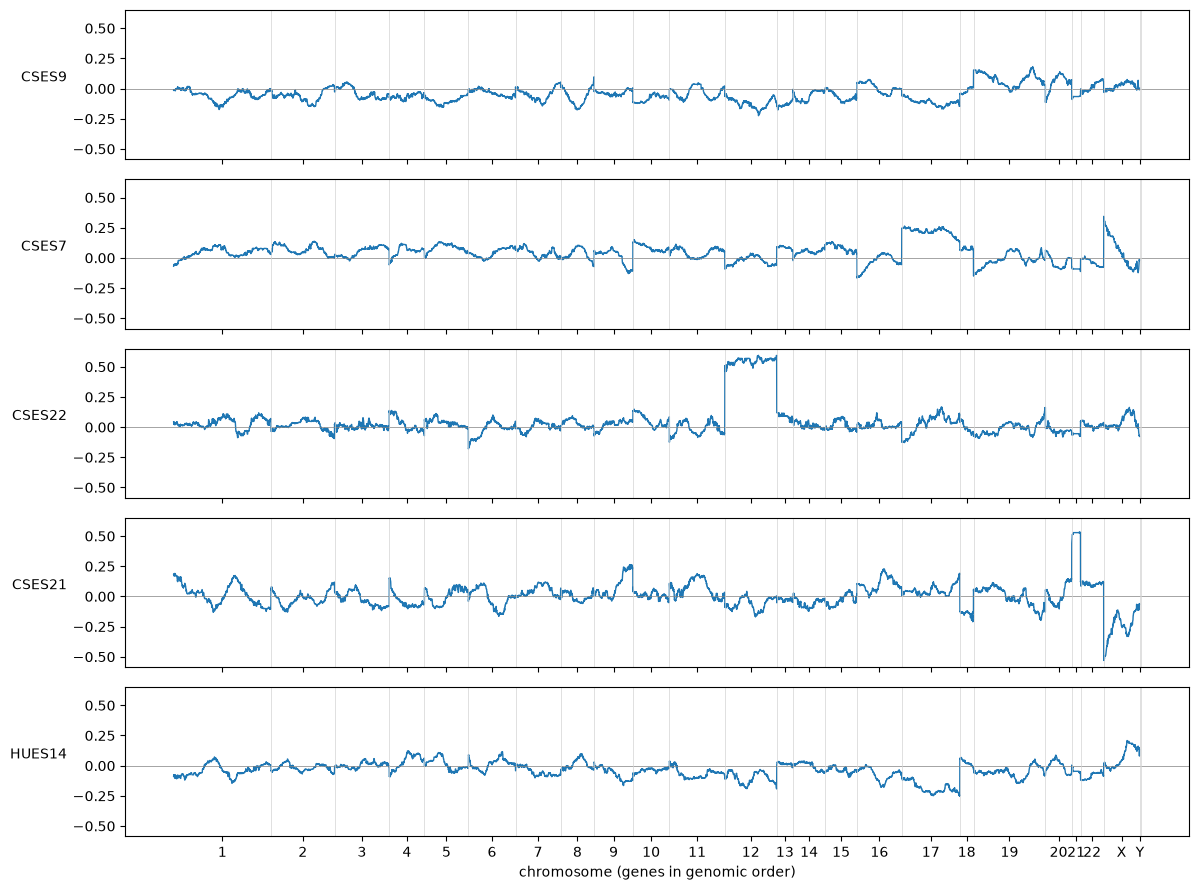

In [2]:
# leave-one-out baseline: each line vs the median of the OTHER four
lc = logcpm.loc[genes.index]
ratio2 = pd.DataFrame(index=lc.index)
for s in lc.columns:
    ratio2[s] = lc[s] - lc.drop(columns=s).median(axis=1)

chrom_median2 = ratio2.groupby(genes["chrom"]).median()
chrom_median2 = chrom_median2.loc[sorted(chrom_median2.index, key=lambda c: order[c])]
print(chrom_median2.round(2))

smooth2 = pd.DataFrame(index=ratio2.index)
for s in ratio2.columns:
    smooth2[s] = ratio2[s].groupby(genes["chrom"]).transform(
        lambda x: x.rolling(WINDOW, center=True, min_periods=WINDOW // 2).median())

fig, axes = plt.subplots(len(smooth2.columns), 1, figsize=(12, 9), sharex=True, sharey=True)
x = np.arange(len(smooth2))
for ax, s in zip(axes, smooth2.columns):
    ax.plot(x, smooth2[s].values, lw=1)
    ax.axhline(0, color="grey", lw=0.5)
    for b in bounds:
        ax.axvline(b, color="lightgrey", lw=0.5)
    ax.set_ylabel(s, rotation=0, ha="right")
axes[-1].set_xticks(mid)
axes[-1].set_xticklabels(names.values)
axes[-1].set_xlabel("chromosome (genes in genomic order)")
plt.tight_layout()
plt.savefig("../figures/leave_one_out_profile.png", dpi=150)
plt.show()